# Project 4: Capacity-constrained spatial clustering with a network cost estimate

**Objective.** Group facility locations into service clusters that are balanced in size, and estimate the cabling needed to connect each cluster. Compare a capacity-constrained method with ordinary k-means on the same points.

**Problem.** Ordinary k-means puts centres where points are dense, so clusters can be very uneven. An uneven cluster may be cheap in total distance but expensive to serve. A balanced partition can cost more in distance. The question is how much cabling a balance constraint adds.

**Data.** All inputs are **synthetic** and generated with a fixed seed. The study area is an irregular polygon in UTM 33N metres. The facility points come from six unequal hotspots inside it. Nothing here reflects a real region, real facilities or real network infrastructure.

**Method.**
- Capacitated k-means: Lloyd iterations where the assignment step is an exact min-cost assignment with a per-cluster capacity (Hungarian algorithm over repeated centre slots).
- Network cost: minimum spanning tree (MST) length of the points in each cluster, which approximates the shortest cable needed to link them.
- Cohesion: diameter of each cluster, and silhouette score.

## 1. Imports and configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../src").resolve()))
from spatial_clusters import (
    CRS, capacitated_kmeans, capacity_for, compare_methods, facility_points,
    mst_length_km, study_area, unconstrained_kmeans, validate_points, validate_study_area,
)

SEED = 0
N_POINTS = 600
K = 6
SLACK = 0.10
SLACK_SWEEP = [0.0, 0.05, 0.10, 0.20, 0.50]
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 2. Build and validate the inputs
The area must be a valid polygon and every point must lie inside it, with no duplicates or non-finite coordinates. These checks run before any clustering.

In [2]:
area = validate_study_area(study_area())
points = validate_points(facility_points(area, n_points=N_POINTS, seed=SEED), area)

from scipy.spatial import cKDTree
tree = cKDTree(points)
nn_dist, _ = tree.query(points, k=2)

qa = pd.Series({
    "CRS": CRS,
    "study area (km2)": round(area.area / 1e6, 1),
    "points": len(points),
    "points per km2": round(len(points) / (area.area / 1e6), 1),
    "median nearest-neighbour distance (m)": round(float(np.median(nn_dist[:, 1])), 0),
    "points valid and inside area": True,
}, name="value")
qa

CRS                                      EPSG:32633
study area (km2)                             1287.6
points                                          600
points per km2                                  0.5
median nearest-neighbour distance (m)         343.0
points valid and inside area                   True
Name: value, dtype: object

**Quality checks.** The area is a valid polygon in metres, all 600 points are inside it, and the distances are in metres. The nearest-neighbour distance is a sanity check on the point spacing.

## 3. Study area and facility points

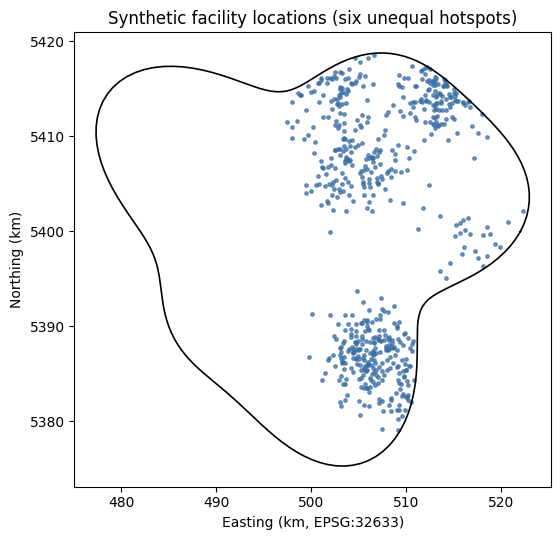

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
x, y = area.exterior.xy
ax.plot(np.asarray(x) / 1000, np.asarray(y) / 1000, color="black", lw=1.2)
ax.scatter(points[:, 0] / 1000, points[:, 1] / 1000, s=6, color="#3b6ea5", alpha=0.7)
ax.set_title("Synthetic facility locations (six unequal hotspots)")
ax.set_xlabel("Easting (km, EPSG:32633)")
ax.set_ylabel("Northing (km)")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG_DIR / "facilities.png", dpi=120)
plt.show()

## 4. Ordinary k-means and capacitated k-means
The capacity is an equal share of points per cluster plus the slack. Both methods use the same seed and the same initial centres.

In [4]:
cap = capacity_for(len(points), K, slack=SLACK)
plain = unconstrained_kmeans(points, K, seed=SEED)
constrained = capacitated_kmeans(points, K, capacity=cap, seed=SEED)
print(f"Capacity per cluster: {cap} (equal share {len(points) / K:.0f}, slack {SLACK:.0%})")
print(f"Iterations: k-means {plain.n_iter}, capacitated {constrained.n_iter}")

table = compare_methods(points, [plain, constrained])
table

Capacity per cluster: 111 (equal share 100, slack 10%)
Iterations: k-means 9, capacitated 5


,largest cluster,smallest cluster,total MST (km),largest diameter (km),silhouette
method,,,,,
kmeans,152,28,317.5,12.3,0.478
capacitated_kmeans,111,48,329.1,19.3,0.413


**How to read this.** The table compares cluster balance, the total MST cable length across all clusters, the largest cluster diameter, and the silhouette score. A lower total MST and a smaller diameter both mean less network cost. The silhouette score measures cohesion and separation, so it is shown for reference rather than as a target.

## 5. Clusters from both methods

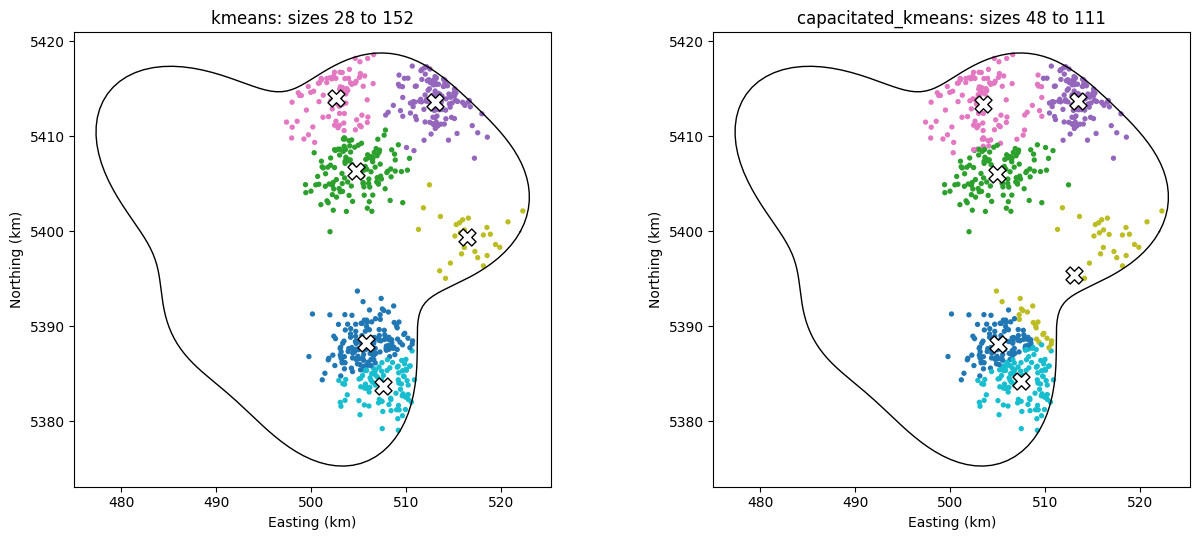

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, res in zip(axes, [plain, constrained]):
    ax.plot(np.asarray(x) / 1000, np.asarray(y) / 1000, color="black", lw=1)
    ax.scatter(points[:, 0] / 1000, points[:, 1] / 1000, c=res.labels, cmap="tab10", s=8)
    ax.scatter(res.centres[:, 0] / 1000, res.centres[:, 1] / 1000, marker="X", s=150,
               facecolor="white", edgecolor="black", zorder=5)
    sizes = np.bincount(res.labels)
    ax.set_title(f"{res.method}: sizes {sizes.min()} to {sizes.max()}")
    ax.set_xlabel("Easting (km)")
    ax.set_ylabel("Northing (km)")
    ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG_DIR / "cluster_comparison.png", dpi=120)
plt.show()

## 6. Cluster sizes against the capacity

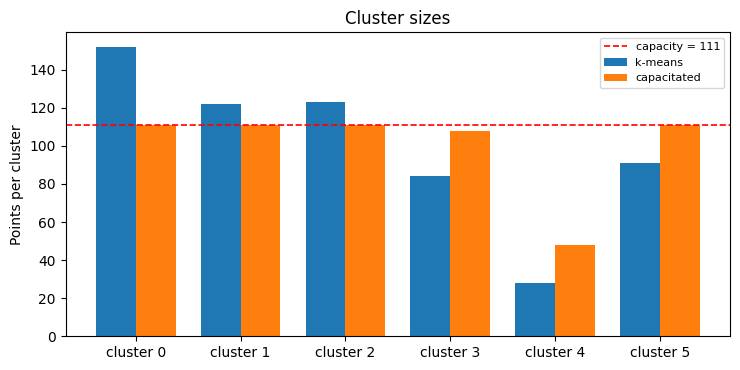

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
w = 0.38
idx = np.arange(K)
ax.bar(idx - w / 2, np.bincount(plain.labels, minlength=K), width=w, label="k-means")
ax.bar(idx + w / 2, np.bincount(constrained.labels, minlength=K), width=w, label="capacitated")
ax.axhline(cap, color="red", ls="--", lw=1.2, label=f"capacity = {cap}")
ax.set_xticks(idx, [f"cluster {i}" for i in idx])
ax.set_ylabel("Points per cluster")
ax.set_title("Cluster sizes")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "cluster_sizes.png", dpi=120)
plt.show()

## 7. Cost of the balance constraint
The slack sets how far a cluster may exceed an equal share. The sweep shows how the network cost changes as the constraint is relaxed. Slack 0 forces the most balanced partition, and slack 0.5 is close to unconstrained.

In [7]:
rows = []
for s in SLACK_SWEEP:
    c = capacity_for(len(points), K, slack=s)
    res = capacitated_kmeans(points, K, capacity=c, seed=SEED)
    m = compare_methods(points, [res]).iloc[0]
    rows.append({"slack": s, "capacity": c, "largest cluster": m["largest cluster"],
                 "smallest cluster": m["smallest cluster"], "total MST (km)": m["total MST (km)"],
                 "largest diameter (km)": m["largest diameter (km)"]})
sweep = pd.DataFrame(rows).set_index("slack")
sweep

,capacity,largest cluster,smallest cluster,total MST (km),largest diameter (km)
slack,,,,,
0.00,100,100.0,100.0,336.6,26.2
0.05,105,105.0,75.0,336.3,21.3
0.10,111,111.0,48.0,329.1,19.3
0.20,120,120.0,31.0,325.2,17.5
0.50,150,150.0,28.0,317.6,12.3


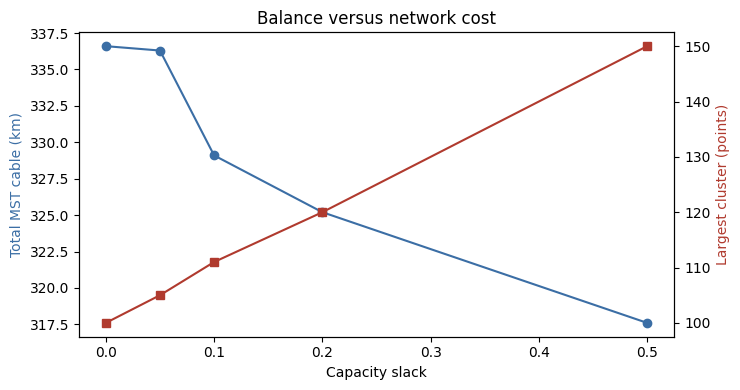

In [8]:
fig, ax1 = plt.subplots(figsize=(7.5, 4))
ax1.plot(sweep.index, sweep["total MST (km)"], marker="o", color="#3b6ea5", label="total MST (km)")
ax1.set_xlabel("Capacity slack")
ax1.set_ylabel("Total MST cable (km)", color="#3b6ea5")
ax2 = ax1.twinx()
ax2.plot(sweep.index, sweep["largest cluster"], marker="s", color="#b03a2e", label="largest cluster")
ax2.set_ylabel("Largest cluster (points)", color="#b03a2e")
ax1.set_title("Balance versus network cost")
fig.tight_layout()
fig.savefig(FIG_DIR / "slack_tradeoff.png", dpi=120)
plt.show()

**Is this stable across layouts?** One layout can mislead, so the check below repeats the comparison on five facility layouts (seeds 0 to 4), each with its own k-means and capacitated run at 10% slack.

In [9]:
rel = []
for s in range(5):
    pts_s = validate_points(facility_points(area, n_points=N_POINTS, seed=s), area)
    pl_s = unconstrained_kmeans(pts_s, K, seed=s)
    cc_s = capacitated_kmeans(pts_s, K, capacity=cap, seed=s)
    t = compare_methods(pts_s, [pl_s, cc_s])
    rel.append({
        "layout seed": s,
        "MST change (%)": 100 * (t.loc["capacitated_kmeans", "total MST (km)"] / t.loc["kmeans", "total MST (km)"] - 1),
        "largest diameter change (%)": 100 * (t.loc["capacitated_kmeans", "largest diameter (km)"] / t.loc["kmeans", "largest diameter (km)"] - 1),
        "k-means largest cluster": t.loc["kmeans", "largest cluster"],
    })
rel = pd.DataFrame(rel).set_index("layout seed").round(1)
rel.loc["mean"] = rel.mean().round(1)
rel.loc["std"] = rel.iloc[:-1].std().round(1)
rel

,MST change (%),largest diameter change (%),k-means largest cluster
layout seed,,,
0,3.7,56.9,152.0
1,4.2,39.3,125.0
2,3.0,13.9,161.0
3,2.1,28.5,188.0
4,8.3,38.4,189.0
mean,4.3,35.4,163.0
std,2.4,15.8,26.8


## 8. Interpretation, limitations and next steps

**Result 1: balance is cheap in cable but expensive in spread.** On the main layout, the capacitated partition has cluster sizes from 48 to 111 points, against 28 to 152 for k-means. Its total MST cable is 329 km, against 318 km for k-means, which is a 3.7% increase. Across five layouts the cable increase averages 4.3%, and ranges from 2.1% to 8.3%.

**Result 2: the cost shows up as larger cluster diameters.** The largest diameter rises from 12.3 km under k-means to 19.3 km on the main layout. Across layouts the rise averages 35%, with a wide spread. The capacity forces some points into clusters whose centres are far away, so clusters become spatially spread out even though total cabling barely changes. For service planning, the diameter (the longest link a cluster needs) may matter more than the total cable.

**Result 3: the slack gives a usable dial.** At zero slack, every cluster must hold exactly 100 points, and the total cable is 337 km. At 50% slack the total is 318 km, which is almost the k-means value. The largest cluster is 150 points. The total cable changes by only about 6% across the whole range, but the diameter changes by more than twice that. So the diameter is the more sensitive indicator when choosing a slack.

**Result 4: the silhouette score falls with balance.** It drops from 0.48 for k-means to 0.41 for the capacitated run on the main layout. This is expected. The constraint moves some boundary points away from their nearest centre, which lowers cohesion. The silhouette score therefore reports a real cost of the constraint, but it does not measure whether the partition is useful.

**Limitations**

- The points come from six hotspots by design, so the density differences are strong. Real facility distributions may be less clustered, and the trade-off would change.
- The MST is a proxy for cabling. Real networks need routes along roads or rights of way, with terrain and cost weights, and none of these are modelled.
- Capacitated k-means is a local search. Its result depends on the starting centres, and it is not guaranteed to be the global optimum for the capacity-constrained problem. The check across five layouts is a sample, not a proof.
- The capacity is set as an equal share plus slack. Real service constraints may be different, such as travel time, demand weights or maximum distance to a centre.
- Only one run per layout was made for each method. Seed-to-seed variation within a layout has not been measured.

**Next steps**

- Add demand weights to the capacity constraint, so that clusters balance demand rather than point counts.
- Replace the MST with a routed network on a real or synthetic road graph (NetworkX or a routing engine), and compare the two cost measures.
- Add a maximum-diameter constraint, and measure how many points must be reassigned to meet it.
- Repeat the layout check with more seeds and report confidence intervals.